<a href="https://colab.research.google.com/github/ShamaimI/ANN-DL/blob/main/Lab_Assign_01_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tasks-1

1. Apply Maccllouch Pitts neural model to solve logical gates given below.

2. Implement a generic M-P neuron function mp_neuron(inputs, weights, threshold).

3. Using the M-P neuron, realize the following logic gates by manually choosing weights and threshold — show your derivation for each:

o AND gate (2-input)

o OR gate (2-input)

o NOT gate (1-input, use a negative weight)

o AND gate for 3 inputs

4. Attempt to realize the XOR gate using a single M-P neuron.

5. Print a truth table for each gate showing inputs, weighted sum, and output.

### 1. Derivations for Logic Gates using McCulloch-Pitts Neuron

A McCulloch-Pitts (M-P) neuron fires (output = 1) if the weighted sum of its inputs is greater than or equal to a threshold $\theta$:
$$\sum_{i=1}^{n} w_i x_i \ge \theta$$
Otherwise, the output is 0.

#### **A. 2-Input AND Gate**
* **Inputs**: $x_1, x_2 \in \{0, 1\}$
* **Weights**: Let $w_1 = 1, w_2 = 1$
* **Threshold**: Let $\theta = 2$
* **Derivation/Verification**:
  * For $(0, 0)$: $1(0) + 1(0) = 0 < 2 \rightarrow$ Output = 0
  * For $(0, 1)$: $1(0) + 1(1) = 1 < 2 \rightarrow$ Output = 0
  * For $(1, 0)$: $1(1) + 1(0) = 1 < 2 \rightarrow$ Output = 0
  * For $(1, 1)$: $1(1) + 1(1) = 2 \ge 2 \rightarrow$ Output = 1

#### **B. 2-Input OR Gate**
* **Inputs**: $x_1, x_2 \in \{0, 1\}$
* **Weights**: Let $w_1 = 1, w_2 = 1$
* **Threshold**: Let $\theta = 1$
* **Derivation/Verification**:
  * For $(0, 0)$: $1(0) + 1(0) = 0 < 1 \rightarrow$ Output = 0
  * For $(0, 1)$: $1(0) + 1(1) = 1 \ge 1 \rightarrow$ Output = 1
  * For $(1, 0)$: $1(1) + 1(0) = 1 \ge 1 \rightarrow$ Output = 1
  * For $(1, 1)$: $1(1) + 1(1) = 2 \ge 1 \rightarrow$ Output = 1

#### **C. NOT Gate**
* **Inputs**: $x_1 \in \{0, 1\}$
* **Weights**: Let $w_1 = -1$ (negative weight for inhibitory action)
* **Threshold**: Let $\theta = 0$
* **Derivation/Verification**:
  * For $(0)$: $-1(0) = 0 \ge 0 \rightarrow$ Output = 1
  * For $(1)$: $-1(1) = -1 < 0 \rightarrow$ Output = 0

#### **D. 3-Input AND Gate**
* **Inputs**: $x_1, x_2, x_3 \in \{0, 1\}$
* **Weights**: Let $w_1 = 1, w_2 = 1, w_3 = 1$
* **Threshold**: Let $\theta = 3$
* **Derivation/Verification**:
  * Fires only when all inputs are 1: $1(1) + 1(1) + 1(1) = 3 \ge 3 \rightarrow$ Output = 1. Any other combination yields a sum $< 3$ and output = 0.

---

### **4. XOR Gate Realization Attempt**
* **Goal**: Realize XOR gate ($x_1 \oplus x_2$) using a single M-P neuron.
* **System of Inequalities**:
  1. $x_1=0, x_2=0 \rightarrow w_1(0) + w_2(0) < \theta \implies 0 < \theta$
  2. $x_1=0, x_2=1 \rightarrow w_1(0) + w_2(1) \ge \theta \implies w_2 \ge \theta$
  3. $x_1=1, x_2=0 \rightarrow w_1(1) + w_2(0) \ge \theta \implies w_1 \ge \theta$
  4. $x_1=1, x_2=1 \rightarrow w_1(1) + w_2(1) < \theta \implies w_1 + w_2 < \theta$
* **Contradiction**:
  From (1), $\theta > 0$.
  From (2) and (3), both $w_1$ and $w_2$ must be positive values at least as large as $\theta$. Therefore, $w_1 + w_2 \ge 2\theta$. Since $\theta > 0$, it is impossible for $w_1 + w_2 < \theta$ to hold true.
* **Conclusion**: A single M-P neuron **cannot** realize the XOR gate because the XOR function is not linearly separable.

In [ ]:
def print_truth_table(gate_name, inputs_list, weights, threshold):

    print(f"=== {gate_name} ===")
    print(f"Weights: {weights}, Threshold: {threshold}")

    num_inputs = len(inputs_list[0])
    input_headers = " ".join([f"X{i+1}" for i in range(num_inputs)])
    print(f"{input_headers} | Weighted Sum | Output")
    print("-" * (len(input_headers) + 26))

    for inputs in inputs_list:
        weighted_sum, output = mp_neuron(inputs, weights, threshold)
        input_str = "   ".join(map(str, inputs))
        print(f" {input_str}  | {weighted_sum:12} | {output:6}")
    print("\n")

print_truth_table(
    "AND Gate (2-input)",
    [[0, 0], [0, 1], [1, 0], [1, 1]],
    weights=[1, 1],
    threshold=2
)

print_truth_table(
    "OR Gate (2-input)",
    [[0, 0], [0, 1], [1, 0], [1, 1]],
    weights=[1, 1],
    threshold=1
)

print_truth_table(
    "NOT Gate",
    [[0], [1]],
    weights=[-1],
    threshold=0
)

print_truth_table(
    "AND Gate (3-input)",
    [
        [0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1],
        [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]
    ],
    weights=[1, 1, 1],
    threshold=3
)

=== AND Gate (2-input) ===
Weights: [1, 1], Threshold: 2
X1 X2 | Weighted Sum | Output
-------------------------------
 0   0  |            0 |      0
 0   1  |            1 |      0
 1   0  |            1 |      0
 1   1  |            2 |      1


=== OR Gate (2-input) ===
Weights: [1, 1], Threshold: 1
X1 X2 | Weighted Sum | Output
-------------------------------
 0   0  |            0 |      0
 0   1  |            1 |      1
 1   0  |            1 |      1
 1   1  |            2 |      1


=== NOT Gate ===
Weights: [-1], Threshold: 0
X1 | Weighted Sum | Output
----------------------------
 0  |            0 |      1
 1  |           -1 |      0


=== AND Gate (3-input) ===
Weights: [1, 1, 1], Threshold: 3
X1 X2 X3 | Weighted Sum | Output
----------------------------------
 0   0   0  |            0 |      0
 0   0   1  |            1 |      0
 0   1   0  |            1 |      0
 0   1   1  |            2 |      0
 1   0   0  |            1 |      0
 1   0   1  |            2 |      0


Tasks-2

1. Implement a Perceptron class with fit(X, y, epochs, lr) and predict(X) methods, using a step activation function.

2. Train it on the AND and OR truth tables. Plot the decision boundary after training (2D plot with the separating line).

3. Plot the number of misclassifications per epoch to show convergence.

4. Attempt to train the same perceptron on the XOR truth table.

o Show that it fails to converge (plot the error curve — it will not go to zero).

o Explain the failure in terms of linear separability (include a sketch/plot of the XOR points showing no straight line can separate them).


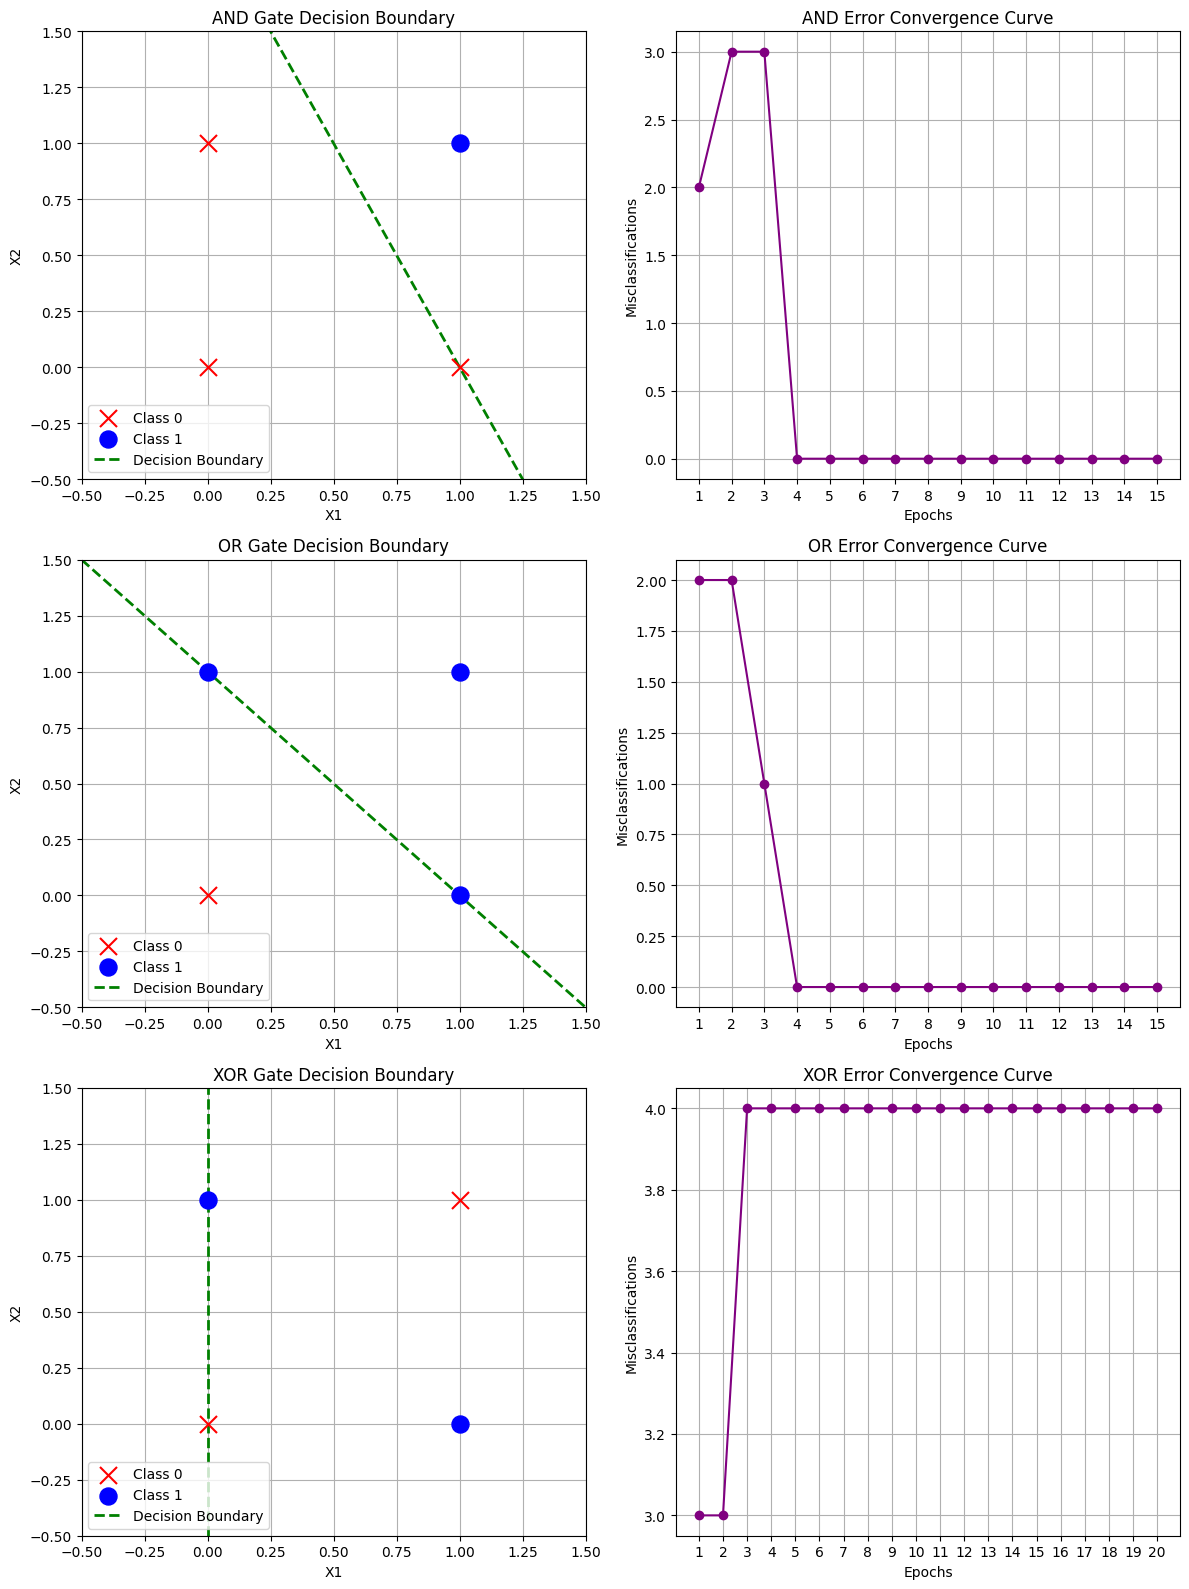

=== Linear Separability Explanation ===
1. AND & OR gates converge quickly because their classes are linearly separable.
2. XOR gate fails to converge (the error curve remains above zero) because its classes cannot be
   separated by a single straight line (linearly inseparable). Classes are configured diagonally.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class Perceptron:
    def __init__(self, input_size):
        self.weights = np.zeros(input_size)
        self.bias = 0.0
        self.errors = []

    def activation(self, x):
        return 1 if x >= 0 else 0

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.activation(linear_output)

    def fit(self, X, y, epochs=20, lr=0.1):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.errors = []

        for epoch in range(epochs):
            error_count = 0
            for xi, target in zip(X, y):
                prediction = self.predict(xi)
                update = lr * (target - prediction)
                if update != 0:
                    self.weights += update * xi
                    self.bias += update
                    error_count += 1
            self.errors.append(error_count)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

gates = {
    "AND": (y_and, 15, 0.1),
    "OR": (y_or, 15, 0.1),
    "XOR": (y_xor, 20, 0.1)
}

fig, axes = plt.subplots(3, 2, figsize=(12, 16))

for i, (name, (y, epochs, lr)) in enumerate(gates.items()):
    clf = Perceptron(input_size=2)
    clf.fit(X, y, epochs=epochs, lr=lr)

    ax_db = axes[i, 0]
    for inputs, target in zip(X, y):
        marker = 'o' if target == 1 else 'x'
        color = 'blue' if target == 1 else 'red'
        ax_db.scatter(inputs[0], inputs[1], marker=marker, color=color, s=150, zorder=3, label=f'Class {target}' if f'Class {target}' not in ax_db.get_legend_handles_labels()[1] else "")


    if clf.weights[1] != 0:
        x_vals = np.linspace(-0.5, 1.5, 100)
        y_vals = -(clf.weights[0] * x_vals + clf.bias) / clf.weights[1]
        ax_db.plot(x_vals, y_vals, '--g', label='Decision Boundary', linewidth=2)
    elif clf.weights[0] != 0:
        x_val = -clf.bias / clf.weights[0]
        ax_db.axvline(x=x_val, color='g', linestyle='--', label='Decision Boundary', linewidth=2)

    ax_db.set_title(f"{name} Gate Decision Boundary")
    ax_db.set_xlabel("X1")
    ax_db.set_ylabel("X2")
    ax_db.set_xlim(-0.5, 1.5)
    ax_db.set_ylim(-0.5, 1.5)
    ax_db.grid(True)
    ax_db.legend(loc='lower left')

    ax_err = axes[i, 1]
    ax_err.plot(range(1, len(clf.errors) + 1), clf.errors, marker='o', color='purple')
    ax_err.set_title(f"{name} Error Convergence Curve")
    ax_err.set_xlabel("Epochs")
    ax_err.set_ylabel("Misclassifications")
    ax_err.set_xticks(range(1, len(clf.errors) + 1))
    ax_err.grid(True)

plt.tight_layout()
plt.show()

print("=== Linear Separability Explanation ===")
print("1. AND & OR gates converge quickly because their classes are linearly separable.")
print("2. XOR gate fails to converge (the error curve remains above zero) because its classes cannot be")
print("   separated by a single straight line (linearly inseparable). Classes are configured diagonally.")

Tasks-3

Implement a 2-layer MLP from scratch (input → hidden layer with sigmoid → output layer with sigmoid) using NumPy — no deep learning frameworks.

1. Implement forward propagation and backpropagation (derive and code the gradients manually).

2. Train the MLP on the XOR problem until the loss converges near zero. Use at least 2 hidden neurons.

3. Plot:

o Loss (mean squared error) vs. epoch

o The learned decision boundary (should now correctly separate XOR)

4. Experiment: vary the number of hidden neurons (2, 4, 8) and the learning rate (0.01, 0.1, 1.0). Tabulate how many epochs each configuration needs to converge.


# Tasks-3: 2-Layer MLP from Scratch for XOR

### 1. Mathematical Derivations

#### **Forward Propagation**
Let $X$ be the input matrix of shape $(N, 2)$.
* **Hidden Layer**:
  $$Z^{(1)} = X W^{(1)} + b^{(1)}$$
  $$A^{(1)} = \sigma(Z^{(1)})$$
  Where $W^{(1)}$ is of shape $(2, H)$, $b^{(1)}$ is of shape $(1, H)$, and $\sigma(z) = \frac{1}{1 + e^{-z}}$.
* **Output Layer**:
  $$Z^{(2)} = A^{(1)} W^{(2)} + b^{(2)}$$
  $$\hat{y} = A^{(2)} = \sigma(Z^{(2)})$$
  Where $W^{(2)}$ is of shape $(H, 1)$ and $b^{(2)}$ is of shape $(1, 1)$.

#### **Loss Function**
We use Mean Squared Error (MSE):
$$L = \frac{1}{2N} \sum (y - \hat{y})^2$$

#### **Backpropagation (Gradients)**
* **Output Layer Gradients**:
  $$\delta^{(2)} = \frac{\partial L}{\partial Z^{(2)}} = \frac{\partial L}{\partial \hat{y}} \odot \sigma'(Z^{(2)}) = -\frac{1}{N} (y - \hat{y}) \odot \hat{y} \odot (1 - \hat{y})$$
  $$\frac{\partial L}{\partial W^{(2)}} = (A^{(1)})^T \delta^{(2)}$$
  $$\frac{\partial L}{\partial b^{(2)}} = \sum_{\text{rows}} \delta^{(2)}$$
* **Hidden Layer Gradients**:
  $$\delta^{(1)} = \frac{\partial L}{\partial Z^{(1)}} = (\delta^{(2)} (W^{(2)})^T) \odot \sigma'(Z^{(1)}) = (\delta^{(2)} (W^{(2)})^T) \odot A^{(1)} \odot (1 - A^{(1)})$$
  $$\frac{\partial L}{\partial W^{(1)}} = X^T \delta^{(1)}$$
  $$\frac{\partial L}{\partial b^{(1)}} = \sum_{\text{rows}} \delta^{(1)}$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):
    return a * (1 - a)

class MLP:
    def __init__(self, input_size=2, hidden_size=2, output_size=1):

        self.W1 = np.random.randn(input_size, hidden_size) * 0.1
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.1
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = sigmoid(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    def backward(self, X, y, lr):
        N = X.shape[0]
        y = y.reshape(-1, 1)

        d_loss_d_A2 = -(y - self.A2) / N
        dZ2 = d_loss_d_A2 * sigmoid_derivative(self.A2)

        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dZ1 = np.dot(dZ2, self.W2.T) * sigmoid_derivative(self.A1)

        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        self.W2 -= lr * dW2
        self.b2 -= lr * db2
        self.W1 -= lr * dW1
        self.b1 -= lr * db1

    def fit(self, X, y, epochs=10000, lr=0.1, stop_threshold=0.001):
        losses = []
        for epoch in range(epochs):
            pred = self.forward(X)
            loss = 0.5 * np.mean((y.reshape(-1, 1) - pred) ** 2)
            losses.append(loss)

            self.backward(X, y, lr)

            if loss < stop_threshold:
                return losses, epoch + 1
        return losses, epochs

/tmp/ipykernel_555/2527206703.py:26: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax_db.scatter(inputs[0], inputs[1], marker=marker, color=color, s=200, edgecolor='k', zorder=5)


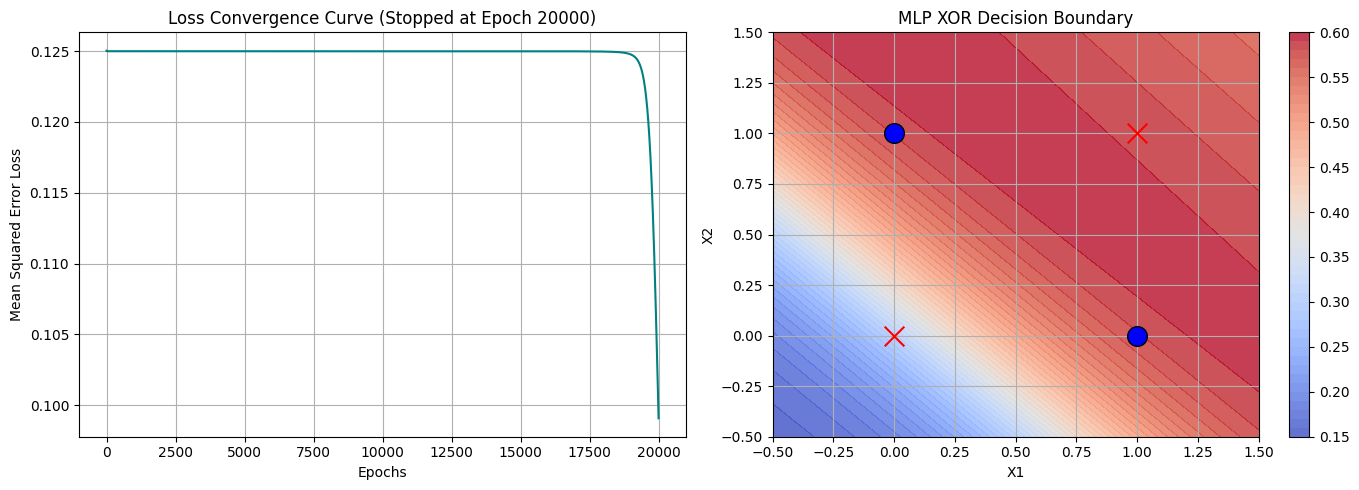

In [ ]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

mlp = MLP(input_size=2, hidden_size=4, output_size=1)
losses, epochs_run = mlp.fit(X_xor, y_xor, epochs=20000, lr=1.0, stop_threshold=0.001)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(losses, color='teal')
axes[0].set_title(f"Loss Convergence Curve (Stopped at Epoch {epochs_run})")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Mean Squared Error Loss")
axes[0].grid(True)

ax_db = axes[1]
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 100), np.linspace(-0.5, 1.5, 100))
grid_points = np.c_[xx.ravel(), yy.ravel()]
preds = mlp.forward(grid_points).reshape(xx.shape)

contour = ax_db.contourf(xx, yy, preds, levels=50, cmap="coolwarm", alpha=0.8)
fig.colorbar(contour, ax=ax_db)

for inputs, target in zip(X_xor, y_xor):
    marker = 'o' if target == 1 else 'x'
    color = 'blue' if target == 1 else 'red'
    ax_db.scatter(inputs[0], inputs[1], marker=marker, color=color, s=200, edgecolor='k', zorder=5)

ax_db.set_title("MLP XOR Decision Boundary")
ax_db.set_xlabel("X1")
ax_db.set_ylabel("X2")
ax_db.set_xlim(-0.5, 1.5)
ax_db.set_ylim(-0.5, 1.5)
ax_db.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
hidden_configurations = [2, 4, 8]
learning_rates = [0.01, 0.1, 1.0]
results = []

for h in hidden_configurations:
    for lr in learning_rates:
        print(f"Testing with Hidden Neurons: {h}, Learning Rate: {lr}")
        success_epochs = []
        for trial in range(5):
            test_mlp = MLP(input_size=2, hidden_size=h, output_size=1)
            _, epochs_to_converge = test_mlp.fit(X_xor, y_xor, epochs=30000, lr=lr, stop_threshold=0.002)
            if epochs_to_converge < 30000:
                success_epochs.append(epochs_to_converge)

        avg_epochs = int(np.mean(success_epochs)) if len(success_epochs) > 0 else "Failed to Converge"
        results.append({
            "Hidden Neurons": h,
            "Learning Rate": lr,
            "Avg Epochs to Converge (Successful Trials)": avg_epochs,
            "Convergence Success Rate": f"{len(success_epochs)}/5"
        })

df_results = pd.DataFrame(results)
display(df_results)

Testing with Hidden Neurons: 2, Learning Rate: 0.01
Testing with Hidden Neurons: 2, Learning Rate: 0.1
Testing with Hidden Neurons: 2, Learning Rate: 1.0
Testing with Hidden Neurons: 4, Learning Rate: 0.01
Testing with Hidden Neurons: 4, Learning Rate: 0.1
Testing with Hidden Neurons: 4, Learning Rate: 1.0
Testing with Hidden Neurons: 8, Learning Rate: 0.01
Testing with Hidden Neurons: 8, Learning Rate: 0.1
Testing with Hidden Neurons: 8, Learning Rate: 1.0


,Hidden Neurons,Learning Rate,Avg Epochs to Converge (Successful Trials),Convergence Success Rate
0,2,0.01,Failed to Converge,0/5
1,2,0.10,Failed to Converge,0/5
2,2,1.00,19150,1/5
3,4,0.01,Failed to Converge,0/5
4,4,0.10,Failed to Converge,0/5
5,4,1.00,19335,4/5
6,8,0.01,Failed to Converge,0/5
7,8,0.10,Failed to Converge,0/5
8,8,1.00,15035,4/5


Tasks-4

1. Modify your MLP from Part C so the initialization scheme is a parameter (init_method = "zero" | "random" | "xavier" | "he").

2. Train the same XOR MLP under each initialization scheme, keeping all other hyperparameters fixed.

3. For zero initialization, show and explain that the two hidden neurons learn identical weights (symmetry breaking failure) — print the hidden weight matrix after a few epochs to demonstrate this.

4. Plot the loss curves for all four initialization schemes on the same graph for comparison.

5. Tabulate epochs-to-convergence (or final loss after a fixed number of epochs) for each schem


=== Demonstration of Symmetry Breaking Failure (Zero Init) ===
Initial Hidden Weights W1:
 [[0. 0.]
 [0. 0.]]
Hidden Weights W1 after 5 epochs:
 [[0. 0.]
 [0. 0.]]
Explanation: Because all initial weights and biases are identical (zero), both hidden units
receive the exact same input, produce the exact same activation, and receive the identical
gradient updates. They act as a single neuron, making it impossible to solve XOR.



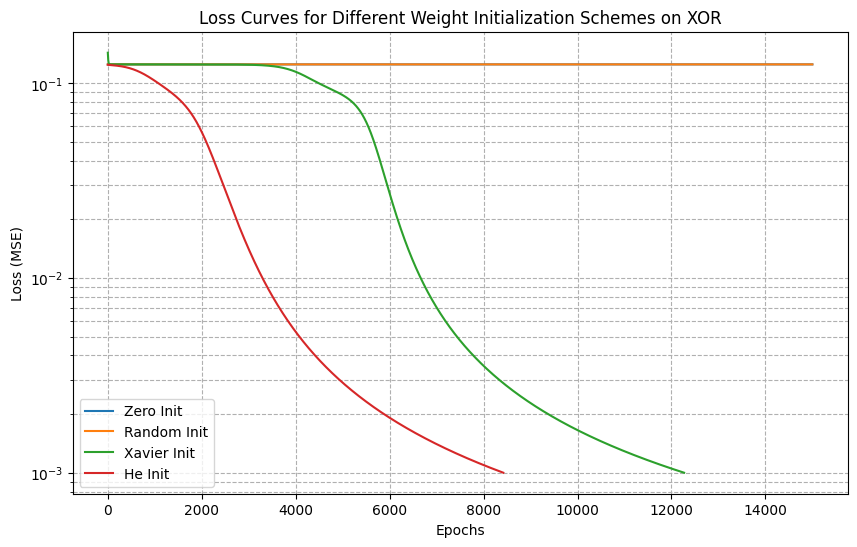

=== Summary of Initialization Scheme Experiments ===


,Initialization Method,Epochs to Converge,Final Loss (MSE)
0,Zero,Did Not Converge,0.125000
1,Random,Did Not Converge,0.125000
2,Xavier,12270,0.001000
3,He,8421,0.001000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):
    return a * (1 - a)

class ConfigurableMLP:
    def __init__(self, input_size=2, hidden_size=2, output_size=1, init_method="random"):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size

        if init_method == "zero":
            self.W1 = np.zeros((input_size, hidden_size))
            self.b1 = np.zeros((1, hidden_size))
            self.W2 = np.zeros((hidden_size, output_size))
            self.b2 = np.zeros((1, output_size))

        elif init_method == "random":
            self.W1 = np.random.randn(input_size, hidden_size) * 0.1
            self.b1 = np.zeros((1, hidden_size))
            self.W2 = np.random.randn(hidden_size, output_size) * 0.1
            self.b2 = np.zeros((1, output_size))

        elif init_method == "xavier":
            limit1 = np.sqrt(2.0 / (input_size + hidden_size))
            self.W1 = np.random.randn(input_size, hidden_size) * limit1
            self.b1 = np.zeros((1, hidden_size))

            limit2 = np.sqrt(2.0 / (hidden_size + output_size))
            self.W2 = np.random.randn(hidden_size, output_size) * limit2
            self.b2 = np.zeros((1, output_size))

        elif init_method == "he":
            self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
            self.b1 = np.zeros((1, hidden_size))
            self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
            self.b2 = np.zeros((1, output_size))
        else:
            raise ValueError(f"Unknown initialization method: {init_method}")

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = sigmoid(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    def backward(self, X, y, lr):
        N = X.shape[0]
        y = y.reshape(-1, 1)

        d_loss_d_A2 = -(y - self.A2) / N
        dZ2 = d_loss_d_A2 * sigmoid_derivative(self.A2)
        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dZ1 = np.dot(dZ2, self.W2.T) * sigmoid_derivative(self.A1)
        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        self.W2 -= lr * dW2
        self.b2 -= lr * db2
        self.W1 -= lr * dW1
        self.b1 -= lr * db1

    def fit(self, X, y, epochs=10000, lr=0.5, stop_threshold=0.001):
        losses = []
        for epoch in range(epochs):
            pred = self.forward(X)
            loss = 0.5 * np.mean((y.reshape(-1, 1) - pred) ** 2)
            losses.append(loss)
            self.backward(X, y, lr)
            if loss < stop_threshold:
                return losses, epoch + 1
        return losses, epochs

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

print("=== Demonstration of Symmetry Breaking Failure (Zero Init) ===")
zero_mlp = ConfigurableMLP(hidden_size=2, init_method="zero")
print("Initial Hidden Weights W1:\n", zero_mlp.W1)
for epoch in range(5):
    zero_mlp.forward(X_xor)
    zero_mlp.backward(X_xor, y_xor, lr=0.5)
print("Hidden Weights W1 after 5 epochs:\n", zero_mlp.W1)
print("Explanation: Because all initial weights and biases are identical (zero), both hidden units")
print("receive the exact same input, produce the exact same activation, and receive the identical")
print("gradient updates. They act as a single neuron, making it impossible to solve XOR.\n")

init_methods = ["zero", "random", "xavier", "he"]
plt.figure(figsize=(10, 6))
tabulated_data = []

for method in init_methods:
    mlp = ConfigurableMLP(hidden_size=4, init_method=method)
    losses, epochs_to_converge = mlp.fit(X_xor, y_xor, epochs=15000, lr=0.5, stop_threshold=0.001)

    plt.plot(losses, label=f"{method.capitalize()} Init")

    tabulated_data.append({
        "Initialization Method": method.capitalize(),
        "Epochs to Converge": epochs_to_converge if epochs_to_converge < 15000 else "Did Not Converge",
        "Final Loss (MSE)": f"{losses[-1]:.6f}"
    })

plt.title("Loss Curves for Different Weight Initialization Schemes on XOR")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.yscale("log")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

print("=== Summary of Initialization Scheme Experiments ===")
df_summary = pd.DataFrame(tabulated_data)
display(df_summary)